# H2: Frozen EfficientNetB0 Baseline for Lung Histopathology

**Experiment ID:** `H2_EfficientNetB0_frozen_seed42`  
**Dataset:** LC25000, lung-only categories (`lung_aca`, `lung_n`, `lung_scc`)  
**Reference baseline:** `H1_MobileNetV2_frozen_seed42`  
**Selection/evaluation scope:** validation only; held-out test remains untouched.

This is a controlled second-backbone experiment. The fixed source-group manifest, image size, class order, class weighting, batch size, seed, optimizer, dropout and checkpoint-selection criterion follow H1. The backbone and its **native preprocessing** differ. LC25000's reconstructed source-image groups are not independent patient or hospital identifiers.

This notebook does not implement stain normalization, stain-aware augmentation, multi-backbone feature fusion, Grad-CAM, or robustness testing. Those approved-methodology tasks require separate documented experiments; H2 is not evidence that they were completed.


## Experimental design and data boundaries

| Partition | Images | Reconstructed source-image groups | Usage |
|---|---:|---:|---|
| Training | 10,394 | 514 | Fit the classification head |
| Validation | 2,273 | 113 | Checkpoint selection and reported metrics |
| Held-out test | 2,333 | 113 | Manifest/hash metadata checks only |
| **Total** | **15,000** | **740** | Lung-only dataset |

| Setting | H2 protocol |
|---|---|
| Backbone | ImageNet EfficientNetB0, frozen (`training=False`) |
| Head | GlobalAveragePooling2D → Dropout(0.2) → Dense(3, softmax) |
| Input | 224 × 224 × 3 padded RGB, float32 near [0,255] |
| Preprocessing | Keras EfficientNetB0 internal Rescaling; no external `[-1,1]` transform |
| Batch / seed | 16 / 42 |
| Optimizer / loss | Adam 0.001 / sparse categorical crossentropy |
| Max epochs / patience | 6 / 2 |
| Best checkpoint | Minimum validation loss |
| Augmentation/fine-tuning | None; frozen backbone |

The two cancer-subtype labels are not diagnostic claims. Source-group separation reduces known augmented-copy leakage but cannot demonstrate patient-level or external-hospital generalization. Values from Sections 9 and 10 are **validation results**, never final test results.


## Storage and reproducibility

Read-only project inputs: `/content/drive/MyDrive/ICTIU_Final_Projects/lung/archives/`, `splits/`, `metadata/`, and the existing audit.  
New outputs only: `/content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42/`.  
Temporary Colab cache: `/content/ictiu_data/lung_h1/` (reused from H1 when still valid; no H1 Drive output changes).

Source archives are **not downloaded again**. Saved split files are never rewritten. The completed-run `evaluate_saved` mode avoids retraining. The temporary cache may be lost after Colab restarts; the source ZIP persists in Drive.


## 1. Drive sources and preparation records

Read the existing LC25000 archive, fixed split manifest, class mapping, original source-group metadata, and audit. Check source-file availability and fingerprint the previously verified manifest. Neither images nor training are run in this section.

In [ ]:
# Read the existing lung source files; no dataset download or split modification.
from google.colab import drive
from pathlib import Path, PurePosixPath
from IPython.display import display
import hashlib
import json
import pandas as pd

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
LUNG = ROOT / 'lung'
SOURCE_FILES = {
    'archive': LUNG / 'archives/LC25000.zip',
    'manifest': LUNG / 'splits/manifest_candidate.csv',
    'mapping': LUNG / 'splits/class_mapping.json',
    'groups': LUNG / 'metadata/lc25000_image_groups.csv',
    'audit': LUNG / 'results/audit.json',
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def read_json(path):
    with Path(path).open(encoding='utf-8-sig') as handle:
        return json.load(handle)

for role, path in SOURCE_FILES.items():
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Missing or empty {role}: {path}')
    print(f'OK: {path.relative_to(LUNG)} ({path.stat().st_size / 1024**2:,.2f} MiB)')

# Read as strings to preserve identifiers such as "001".
raw_manifest = pd.read_csv(SOURCE_FILES['manifest'], dtype=str, keep_default_na=False)
raw_mapping = read_json(SOURCE_FILES['mapping'])
saved_audit = read_json(SOURCE_FILES['audit'])
group_metadata_preview = pd.read_csv(SOURCE_FILES['groups'], dtype=str, nrows=3)
SOURCE_SHA256 = {
    role: sha256_file(path) for role, path in SOURCE_FILES.items() if role != 'archive'
}

print('\nManifest rows:', len(raw_manifest))
print('Manifest columns:', raw_manifest.columns.tolist())
print('\nFirst two manifest records:')
display(raw_manifest.head(2).T)
print('\nSaved class mapping:')
print(json.dumps(raw_mapping, indent=2))
print('\nSource-group metadata columns:', group_metadata_preview.columns.tolist())
display(group_metadata_preview)
print('\nPreparation audit (previously recorded):')
print(json.dumps(saved_audit, indent=2)[:6000])
EXPECTED_MANIFEST_SHA256 = 'd931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea'
if SOURCE_SHA256['manifest'] != EXPECTED_MANIFEST_SHA256:
    raise ValueError('The lung manifest differs from the verified H1 source; do not re-split.')
print('\nData-file checks passed. Original lung manifest SHA-256 matched H1.')


Mounted at /content/drive
OK: archives/LC25000.zip (1,801.84 MiB)
OK: splits/manifest_candidate.csv (2.44 MiB)
OK: splits/class_mapping.json (0.00 MiB)
OK: metadata/lc25000_image_groups.csv (1.19 MiB)
OK: results/audit.json (0.00 MiB)

Manifest rows: 15000
Manifest columns: ['stem', 'relative_path', 'class_name', 'group_id', 'split', 'width', 'height', 'original_mode', 'sha256', 'class_id']

First two manifest records:


,0,1
stem,lungaca1,lungaca10
relative_path,lung_colon_image_set/lung_image_sets/lung_aca/...,lung_colon_image_set/lung_image_sets/lung_aca/...
class_name,lung_aca,lung_aca
group_id,664,668
split,test,validation
width,768,768
height,768,768
original_mode,RGB,RGB
sha256,d6c99a14015399b733b414fb2243b08db077521f2613f0...,ee3ee160449b64e0906260573f51b5969827b04296d41a...
class_id,0,0



Saved class mapping:
{
  "lung_aca": 0,
  "lung_n": 1,
  "lung_scc": 2
}

Source-group metadata columns: ['stem', 'filename', 'label', 'tissue', 'local_cluster_label', 'group_id']


,stem,filename,label,tissue,local_cluster_label,group_id
0,colonca1021,colonca1021.jpeg,colon_aca,colon,0,0
1,colonca1078,colonca1078.jpeg,colon_aca,colon,0,0
2,colonca1139,colonca1139.jpeg,colon_aca,colon,0,0



Preparation audit (previously recorded):
{
  "project": "lung",
  "status": "PASS_candidate_split_checks",
  "images": 15000,
  "classes": [
    "lung_aca",
    "lung_n",
    "lung_scc"
  ],
  "unique_groups": 740,
  "groups_per_split": {
    "test": 113,
    "train": 514,
    "validation": 113
  },
  "images_per_split": {
    "train": 10394,
    "test": 2333,
    "validation": 2273
  },
  "group_overlap": 0,
  "unreadable_images": 0,
  "cross_split_exact_duplicate_hashes": 0,
  "split_seed": 42,
  "manifest_sha256": "d931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea",
  "source_note": "LC25000 lung images; LC25000-clean reconstructed source groups; annotation SHA256=2ff9e992f759f265dfc9aa2363de0dfcc8e6559884d8bb02a4c925214fdf7e23",
  "limitation": "Checks do not prove all biological dependencies were recovered. No model has been trained.",
  "recorded_utc": "2026-10-16T14:36:36.005529+00:00"
}

Data-file checks passed. Original lung manifest SHA-256 matched H1.


## 2. Fixed source-group split and label verification

Validate the original 15,000-row manifest, `lung_aca=0`, `lung_n=1`, `lung_scc=2`, train/validation/test counts, reconstructed source-image groups and recorded hashes. The held-out test contributes **metadata only**. No new split or test image access is permitted.

In [ ]:
# Validate the existing manifest; standardize column access in memory.
EXPECTED_IMAGES = {'train': 10394, 'val': 2273, 'test': 2333}
EXPECTED_GROUPS = {'train': 514, 'val': 113, 'test': 113}
EXPECTED_CLASSES = {'lung_aca', 'lung_n', 'lung_scc'}
COLUMN_OVERRIDES = {
    'path': None, 'split': None, 'class_name': None,
    'class_id': None, 'group': None, 'sha256': None,
}
ALIASES = {
    'path': ['relative_path', 'rel_path', 'relpath', 'image_path', 'filepath', 'file_path',
             'path', 'filename', 'file_name', 'image_name', 'image'],
    'split': ['split', 'subset', 'partition', 'set'],
    'class_name': ['class_name', 'class', 'category', 'label_name', 'label', 'target'],
    'class_id': ['class_id', 'label_id', 'label_idx', 'class_idx', 'target_id'],
    'group': ['group_id', 'source_group_id', 'source_group', 'source_image_group',
              'source_image_group_id', 'original_group_id', 'original_group',
              'source_image_id', 'group'],
    'sha256': ['sha256', 'file_sha256', 'image_sha256', 'sha256_hash'],
}

def choose_column(role, required=False):
    lookup = {str(c).strip().lower(): c for c in raw_manifest.columns}
    override = COLUMN_OVERRIDES[role]
    if override is not None:
        if override not in raw_manifest.columns:
            raise ValueError(f'Unknown override for {role}: {override}')
        return override
    selected = next((lookup[name] for name in ALIASES[role] if name in lookup), None)
    if required and selected is None:
        raise ValueError(f'Required manifest column could not be identified: {role}.')
    return selected

mapping = raw_mapping
if isinstance(mapping, dict) and 'class_to_id' in mapping:
    mapping = mapping['class_to_id']
elif isinstance(mapping, dict) and 'class_to_idx' in mapping:
    mapping = mapping['class_to_idx']
if not isinstance(mapping, dict):
    raise ValueError('Expected a saved class-name-to-ID dictionary.')
if set(mapping) == EXPECTED_CLASSES:
    if any(isinstance(value, bool) or str(value) not in {'0', '1', '2'} for value in mapping.values()):
        raise ValueError('Class-mapping IDs must be the integers 0, 1, 2.')
    class_to_id = {name: int(value) for name, value in mapping.items()}
elif all(str(k).isdigit() for k in mapping) and set(mapping.values()) == EXPECTED_CLASSES:
    class_to_id = {name: int(key) for key, name in mapping.items()}
else:
    raise ValueError(f'Unexpected saved class mapping: {mapping}')
if set(class_to_id.values()) != {0, 1, 2} or len(class_to_id) != 3:
    raise ValueError('Saved class IDs must be exactly 0, 1, 2, with no duplicates.')
class_names = [name for name, index in sorted(class_to_id.items(), key=lambda item: item[1])]
id_to_class = {index: name for name, index in class_to_id.items()}

COLS = {role: choose_column(role, required=role in {'path', 'split', 'group'}) for role in ALIASES}
if COLS['class_name'] is None and COLS['class_id'] is None:
    raise ValueError('No saved class-name or class-ID column was identified.')
print('Selected manifest columns:', json.dumps(COLS, indent=2))

def labels_to_ids(series):
    def convert(value):
        value = str(value).strip()
        if value in class_to_id:
            return class_to_id[value]
        if value in {'0', '1', '2', '0.0', '1.0', '2.0'}:
            return int(float(value))
        raise ValueError(f'Unexpected label in the saved manifest: {value!r}.')
    return series.map(convert).astype('int32')

label_column = COLS['class_name'] or COLS['class_id']
labels = labels_to_ids(raw_manifest[label_column])
if COLS['class_name'] and COLS['class_id']:
    if not labels.equals(labels_to_ids(raw_manifest[COLS['class_id']])):
        raise ValueError('Saved class names and saved class IDs disagree.')

split_aliases = {'train': 'train', 'training': 'train', 'val': 'val',
                 'valid': 'val', 'validation': 'val', 'test': 'test', 'testing': 'test'}
raw_splits = raw_manifest[COLS['split']].str.strip().str.lower()
splits = raw_splits.map(split_aliases)
if splits.isna().any():
    raise ValueError(f'Unrecognized split values: {raw_splits[splits.isna()].unique().tolist()}')
manifest = pd.DataFrame({
    'manifest_row': range(len(raw_manifest)),
    'source_path': raw_manifest[COLS['path']].str.strip(),
    'split': splits,
    'class_id': labels,
    'class_name': labels.map(id_to_class),
    'source_group': raw_manifest[COLS['group']].str.strip(),
})
if (manifest[['source_path', 'source_group']] == '').any().any():
    raise ValueError('The manifest contains empty paths or source groups.')
if manifest['source_path'].duplicated().any():
    raise ValueError('Duplicate image paths in the saved manifest.')
if manifest.groupby('source_group')['split'].nunique().max() != 1:
    raise ValueError('Source-group overlap detected across partitions.')
if manifest.groupby('source_group')['class_name'].nunique().max() != 1:
    raise ValueError('A source group spans multiple classes; group-ID scope is inconsistent.')
image_counts = {k: int(v) for k, v in manifest['split'].value_counts().items()}
group_counts = {k: int(v) for k, v in manifest.groupby('split')['source_group'].nunique().items()}
if image_counts != EXPECTED_IMAGES or group_counts != EXPECTED_GROUPS:
    raise ValueError(f'Split-count mismatch. Images={image_counts}; groups={group_counts}.')
if manifest['source_group'].nunique() != 740:
    raise ValueError('Expected 740 reconstructed source-image groups, not patient groups.')
if manifest['class_name'].value_counts().to_dict() != {name: 5000 for name in EXPECTED_CLASSES}:
    raise ValueError('Expected 5,000 images in each lung class.')
if (pd.crosstab(manifest['split'], manifest['class_name']) == 0).any().any():
    raise ValueError('At least one split is missing a class.')

saved_hashes_checked = COLS['sha256'] is not None
if saved_hashes_checked:
    hashes = raw_manifest[COLS['sha256']].str.strip().str.lower()
    if not hashes.str.fullmatch(r'[0-9a-f]{64}').all():
        raise ValueError('The saved SHA-256 column is incomplete or malformed.')
    manifest['recorded_sha256'] = hashes
    if manifest.groupby('recorded_sha256')['split'].nunique().max() != 1:
        raise ValueError('A saved byte-identical image hash occurs in different partitions.')
else:
    print('No saved SHA-256 column recognized; image-byte checks are limited to training and validation.')

DATA_CHECKS = {
    'image_counts': image_counts, 'source_group_counts': group_counts,
    'total_reconstructed_source_groups': 740, 'groups_spanning_splits': 0,
    'saved_all_split_sha256_checked': saved_hashes_checked,
    'grouping_unit': 'reconstructed source-image group; NOT patient ID',
    'test_image_pixels_read': False,
    'independent_reconstruction_of_source_groups_performed': False,
}
print('\nClass order:', class_names)
display(pd.crosstab(manifest['split'], manifest['class_name']).reindex(['train', 'val', 'test']))
display(pd.DataFrame({'images': image_counts, 'source_groups': group_counts}).reindex(['train', 'val', 'test']))
print('Split validation passed. Source manifest and class mapping are unchanged.')


Selected manifest columns: {
  "path": "relative_path",
  "split": "split",
  "class_name": "class_name",
  "class_id": "class_id",
  "group": "group_id",
  "sha256": "sha256"
}

Class order: ['lung_aca', 'lung_n', 'lung_scc']


class_name,lung_aca,lung_n,lung_scc
split,,,
train,3474,3448,3472
val,758,764,751
test,768,788,777


,images,source_groups
train,10394,514
val,2273,113
test,2333,113


Split validation passed. Source manifest and class mapping are unchanged.


## 3. Runtime, parameters, and output protection

Use a GPU runtime with deterministic settings where supported. A new `H2_EfficientNetB0_frozen_seed42` directory is reserved for H2; H1 is never overwritten. `MODE = 'train_new'` creates a fresh run, while `'evaluate_saved'` reloads completed H2 evidence without retraining.

In [ ]:
# Runtime configuration and fixed H2 parameters.
import os
import sys
import platform
import subprocess
import importlib.metadata
from datetime import datetime, timezone
import numpy as np
import tensorflow as tf
from tensorflow import keras

MODE = 'train_new'  # Options: 'train_new', 'evaluate_saved'.
SMOKE_TEST_PASSED = False  # Reset model-verification state when parameters are reinitialized.
RUN_NAME = 'H2_EfficientNetB0_frozen_seed42'
RUN_DIR = LUNG / 'results' / RUN_NAME
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
MAX_EPOCHS = 6
PATIENCE = 2
LEARNING_RATE = 0.001
DROPOUT = 0.2

if MODE not in {'train_new', 'evaluate_saved'}:
    raise ValueError('MODE must be train_new or evaluate_saved.')
if RUN_NAME != Path(RUN_NAME).name or not RUN_NAME.startswith('H2_'):
    raise ValueError('RUN_NAME must be a filename beginning with H2_, not a path.')
if MODE == 'train_new' and RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise FileExistsError(f'{RUN_DIR} already contains results; train_new cannot overwrite an existing run.')
if MODE == 'evaluate_saved':
    for name in ['configuration.json', 'best_model.keras', 'training_history.csv', 'training_status.json']:
        if not (RUN_DIR / name).is_file():
            raise FileNotFoundError(f'Required saved-run file is missing: {RUN_DIR / name}.')
    SAVED_CONFIG = read_json(RUN_DIR / 'configuration.json')

GPUS = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('Visible GPUs:', GPUS)
if not GPUS:
    raise RuntimeError('No GPU detected. A GPU runtime is required for this experiment.')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # An already initialized GPU can still be used.
keras.mixed_precision.set_global_policy('float32')
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
try:
    gpu_info = subprocess.check_output(
        ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
        text=True, timeout=10,
    ).strip()
except (OSError, subprocess.SubprocessError):
    gpu_info = str(GPUS)

def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not installed under this distribution name'

ENVIRONMENT = {
    'captured_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version, 'platform': platform.platform(),
    'tensorflow': tf.__version__,
    'packages': {name: package_version(name) for name in
                 ['keras', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'pillow', 'tqdm']},
    'gpu': gpu_info, 'float_policy': keras.mixed_precision.global_policy().name,
    'seed': SEED, 'op_determinism_requested': True,
}
print(json.dumps(ENVIRONMENT, indent=2))
print('\nMode:', MODE)
print('Results folder:', RUN_DIR)
print('Runtime configuration complete.')


TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{
  "captured_utc": "2026-10-18T20:28:33.784075+00:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "tensorflow": "2.21.0",
  "packages": {
    "keras": "3.13.2",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "pillow": "11.3.0",
    "tqdm": "4.67.3"
  },
  "gpu": "Tesla T4, 15360 MiB",
  "float_policy": "float32",
  "seed": 42,
  "op_determinism_requested": true
}

Mode: train_new
Results folder: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42
Runtime configuration complete.


## 4. Restore only training and validation images

Reuse the temporary **H1 Colab local archive/image cache** when intact, or restore the verified archive from existing Drive storage. Match members using both class and filename, verify CRC checks, and extract only the 12,667 train/validation images. The H1 *Drive results* are not modified. The held-out test pixels remain untouched.

In [ ]:
# Restore training and validation images from the local archive cache.
import shutil
import stat
import zipfile
import zlib
from collections import defaultdict
from tqdm.auto import tqdm

# Reuse H1's verified LOCAL Colab cache when the runtime still contains it.
# This path is temporary storage; H1's persistent Drive result folder is not modified.
LOCAL_ROOT = Path('/content/ictiu_data/lung_h1')
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_ZIP = LOCAL_ROOT / 'LC25000.zip'
CACHE_INFO = LOCAL_ROOT / 'archive_cache.json'
archive_source = SOURCE_FILES['archive']
source_stat = archive_source.stat()
archive_signature = {
    'source_path': str(archive_source), 'size': source_stat.st_size,
    'mtime_ns': source_stat.st_mtime_ns,
}
cache_ok = False
if LOCAL_ZIP.is_file() and CACHE_INFO.is_file():
    cache = read_json(CACHE_INFO)
    if cache.get('source') == archive_signature and LOCAL_ZIP.stat().st_size == source_stat.st_size:
        print('Checking the existing local archive cache...')
        cache_ok = sha256_file(LOCAL_ZIP) == cache.get('sha256')
if not cache_ok:
    required_space = source_stat.st_size + 1024**3
    if shutil.disk_usage(LOCAL_ROOT).free < required_space:
        raise OSError('Insufficient local disk space for the archive copy.')
    temporary_zip = LOCAL_ROOT / 'LC25000.copying'
    digest = hashlib.sha256()
    with archive_source.open('rb') as source, temporary_zip.open('wb') as target:
        with tqdm(total=source_stat.st_size, unit='B', unit_scale=True, desc='Drive -> local ZIP') as bar:
            for block in iter(lambda: source.read(8 * 1024 * 1024), b''):
                target.write(block)
                digest.update(block)
                bar.update(len(block))
    after = archive_source.stat()
    if (after.st_size, after.st_mtime_ns) != (source_stat.st_size, source_stat.st_mtime_ns):
        raise RuntimeError('The Drive archive changed during copying.')
    if temporary_zip.stat().st_size != source_stat.st_size:
        raise IOError('Incomplete local archive copy.')
    temporary_zip.replace(LOCAL_ZIP)
    cache = {'source': archive_signature, 'sha256': digest.hexdigest()}
    CACHE_INFO.write_text(json.dumps(cache, indent=2), encoding='utf-8')
ARCHIVE_SHA256 = cache['sha256']
EXPECTED_ARCHIVE_SHA256 = '382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728'
if ARCHIVE_SHA256 != EXPECTED_ARCHIVE_SHA256:
    raise ValueError('Local archive checksum differs from the verified H1 LC25000 ZIP.')
print('Local archive SHA-256:', ARCHIVE_SHA256)
if not zipfile.is_zipfile(LOCAL_ZIP):
    raise zipfile.BadZipFile('The saved archive is not a valid ZIP file.')

work_df = manifest[manifest['split'].isin(['train', 'val'])].copy().reset_index(drop=True)
if len(work_df) != EXPECTED_IMAGES['train'] + EXPECTED_IMAGES['val']:
    raise ValueError('Unexpected working split size.')
IMAGE_ROOT = LOCAL_ROOT / ('images_' + ARCHIVE_SHA256[:12])
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def crc32_file(path):
    value = 0
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            value = zlib.crc32(block, value)
    return value & 0xffffffff

with zipfile.ZipFile(LOCAL_ZIP) as archive:
    by_filename = defaultdict(list)
    for info in archive.infolist():
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if info.is_dir() or '__MACOSX' in member.parts or member.name.startswith('._'):
            continue
        if member.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            continue
        classes_in_path = [part for part in member.parts if part in EXPECTED_CLASSES]
        if len(classes_in_path) == 1:
            by_filename[(classes_in_path[0], member.name)].append(info)

    selected = []
    for row in work_df.itertuples(index=False):
        basename = PurePosixPath(row.source_path.replace('\\', '/')).name
        matches = by_filename.get((row.class_name, basename), [])
        if len(matches) != 1:
            raise ValueError(f'Expected one ZIP match for {row.class_name}/{basename}; found {len(matches)}. '
                             'Archive member matching must be unique.')
        info = matches[0]
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if member.is_absolute() or '..' in member.parts or stat.S_ISLNK(info.external_attr >> 16):
            raise ValueError(f'Unsafe ZIP member: {info.filename}')
        selected.append(info)
    if len({info.filename for info in selected}) != len(work_df):
        raise ValueError('Different manifest records resolved to the same archive image.')
    destinations = [IMAGE_ROOT / row.class_name / PurePosixPath(info.filename.replace('\\', '/')).name
                    for row, info in zip(work_df.itertuples(index=False), selected)]
    if len(set(destinations)) != len(destinations):
        raise ValueError('Local filename collision during path resolution.')
    missing_bytes = sum(info.file_size for info, target in zip(selected, destinations) if not target.exists())
    if shutil.disk_usage(LOCAL_ROOT).free < missing_bytes + 512 * 1024**2:
        raise OSError('Insufficient local disk space to restore selected images.')
    restored, reused = 0, 0
    for info, target in tqdm(list(zip(selected, destinations)), desc='Restore train/validation', unit='image'):
        if target.is_file() and target.stat().st_size == info.file_size and crc32_file(target) == info.CRC:
            reused += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        temporary_image = target.with_name(target.name + '.partial')
        with archive.open(info, 'r') as source, temporary_image.open('wb') as output:
            shutil.copyfileobj(source, output, length=1024 * 1024)
        if temporary_image.stat().st_size != info.file_size or crc32_file(temporary_image) != info.CRC:
            raise IOError(f'Image integrity check failed: {info.filename}')
        temporary_image.replace(target)
        restored += 1

work_df['archive_member'] = [info.filename for info in selected]
work_df['local_path'] = [str(path) for path in destinations]
print(f'Restored: {restored:,}; reused: {reused:,}; total: {len(work_df):,}')
print('Image restoration complete. Held-out test images were not extracted.')


Drive -> local ZIP:   0%|          | 0.00/1.89G [00:00<?, ?B/s]

Local archive SHA-256: 382c98315435cbbf559be5da94cc0b62f696434e30e15feefebe9c892de01728


Restore train/validation:   0%|          | 0/12667 [00:00<?, ?image/s]

Restored: 12,667; reused: 0; total: 12,667
Image restoration complete. Held-out test images were not extracted.


## 5. Image verification and input pipelines

Verify decoded image integrity, compare image hashes with the recorded manifest and held-out test **hash metadata**, and create deterministic `tf.data` pipelines. Input is padded, resized to 224 × 224 RGB, and kept as `float32` in approximately `[0,255]`. This range is consumed by Keras EfficientNetB0 **without additional MobileNetV2 scaling**. Training class weights are calculated later from the saved labels; H2 adds no new augmentation.

Verify images:   0%|          | 0/12667 [00:00<?, ?image/s]

Batch shape: (16, 224, 224, 3)
Pixel range: 0.0 to 255.00001525878906
Training batches: 650
Validation batches: 143
Training example: lung_aca | source group: 697


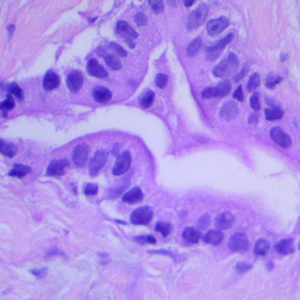

Training example: lung_n | source group: 820


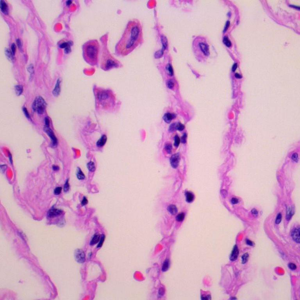

Training example: lung_scc | source group: 1202


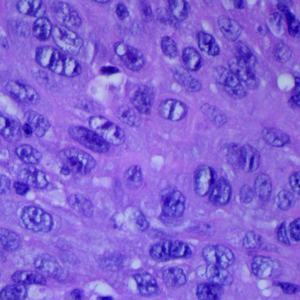

Image verification and input-pipeline checks passed.


In [ ]:
# Verify image bytes and construct input pipelines.
from PIL import Image

computed_hashes = []
for row in tqdm(work_df.itertuples(index=False), total=len(work_df), desc='Verify images', unit='image'):
    try:
        current_hash = sha256_file(row.local_path)
        with Image.open(row.local_path) as image:
            image.load()
            if image.width < 1 or image.height < 1:
                raise ValueError('Empty image dimensions')
            image.convert('RGB')
        if 'recorded_sha256' in work_df.columns and current_hash != row.recorded_sha256:
            raise ValueError('Image bytes differ from the saved manifest SHA-256')
    except Exception as error:
        raise RuntimeError(f'Image verification failed for {row.source_path}: {error}') from error
    computed_hashes.append(current_hash)
work_df['actual_sha256'] = computed_hashes
if work_df.groupby('actual_sha256')['split'].nunique().max() != 1:
    raise ValueError('A byte-identical image occurs in both training and validation.')
if 'recorded_sha256' in manifest.columns:
    test_hashes = set(manifest.loc[manifest['split'].eq('test'), 'recorded_sha256'])
    if set(work_df['actual_sha256']) & test_hashes:
        raise ValueError('A restored image matches a saved held-out test hash.')

train_df = work_df[work_df['split'].eq('train')].copy().reset_index(drop=True)
val_df = work_df[work_df['split'].eq('val')].copy().reset_index(drop=True)
if set(train_df.source_group) & set(val_df.source_group):
    raise ValueError('Training and validation groups overlap.')
DATA_CHECKS.update({
    'working_images_fully_decoded': len(work_df), 'working_unreadable_images': 0,
    'train_val_cross_split_byte_identical_hashes': 0,
    'working_hashes_matched_recorded_sha256': 'recorded_sha256' in work_df.columns,
    'archive_sha256': ARCHIVE_SHA256,
})

def decode_and_resize(path, label):
    contents = tf.io.read_file(path)
    image = tf.io.decode_image(contents, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.cast(image, tf.float32)
    image = tf.image.resize_with_pad(image, IMAGE_SIZE[0], IMAGE_SIZE[1],
                                     method='bilinear', antialias=True)
    image = tf.ensure_shape(image, [IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    if not set(frame['split']).issubset({'train', 'val'}):
        raise ValueError('Held-out test input pipelines are disabled for H2.')
    if training and set(frame['split']) != {'train'}:
        raise ValueError('Only training records may enter the fitting pipeline.')
    dataset = tf.data.Dataset.from_tensor_slices(
        (frame['local_path'].tolist(), frame['class_id'].to_numpy(dtype=np.int32)))
    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(decode_and_resize, num_parallel_calls=tf.data.AUTOTUNE,
                          deterministic=True)
    return dataset.batch(BATCH_SIZE, drop_remainder=False).prefetch(2)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
# Keep preview sampling separate from the training shuffle sequence.
preview_images, preview_labels = next(iter(make_dataset(train_df.head(BATCH_SIZE))))
if tuple(preview_images.shape[1:]) != (*IMAGE_SIZE, 3):
    raise ValueError('Incorrect image tensor shape.')
if not bool(tf.reduce_all(tf.math.is_finite(preview_images))):
    raise ValueError('Non-finite image pixels.')
print('Batch shape:', preview_images.shape)
pixel_min = float(tf.reduce_min(preview_images))
pixel_max = float(tf.reduce_max(preview_images))
if preview_images.dtype != tf.float32 or not (-0.001 <= pixel_min <= pixel_max <= 255.001):
    raise ValueError('EfficientNetB0 requires finite float32 RGB values near [0,255].')
if not bool(tf.reduce_all((preview_labels >= 0) & (preview_labels < len(class_names)))):
    raise ValueError('Preview labels are outside the original three-class mapping.')
print('Pixel range:', pixel_min, 'to', pixel_max)
print('Training batches:', int(tf.data.experimental.cardinality(train_ds)))
print('Validation batches:', int(tf.data.experimental.cardinality(val_ds)))
for name in class_names:
    example = train_df[train_df['class_name'].eq(name)].iloc[0]
    print('Training example:', name, '| source group:', example['source_group'])
    with Image.open(example['local_path']) as image:
        preview = image.convert('RGB')
        preview.thumbnail((300, 300))
        display(preview)
print('Image verification and input-pipeline checks passed.')


## 6. EfficientNetB0 construction and disposable smoke test

Use `EfficientNetB0(include_top=False, weights="imagenet")` with a frozen backbone called in inference mode, followed by `GlobalAveragePooling2D`, `Dropout(0.2)`, and a three-class softmax head. Native EfficientNetB0 preprocessing is already inside the backbone. Verify **3,843 trainable parameters**, fixed backbone weights during a disposable gradient update, probability outputs, and Keras save/load agreement. Discard the smoke-test network before training.

In [ ]:
# Validate a disposable EfficientNetB0 model and its native input preprocessing.
EXPECTED_TRAINABLE_PARAMETERS = (1280 + 1) * len(class_names)  # 3,843 for three classes.

def build_h2_model():
    backbone = keras.applications.EfficientNetB0(
        input_shape=(*IMAGE_SIZE, 3), include_top=False, weights='imagenet')
    backbone.trainable = False
    if not any(isinstance(layer, keras.layers.Rescaling) for layer in backbone.layers):
        raise RuntimeError('Expected built-in EfficientNetB0 rescaling layer was not found.')
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name='rgb_0_255')
    # IMPORTANT: Do not add MobileNetV2 [-1,1] scaling or preprocess_input here.
    features = backbone(inputs, training=False)
    features = keras.layers.GlobalAveragePooling2D(name='global_average_pooling')(features)
    features = keras.layers.Dropout(DROPOUT, seed=SEED, name='head_dropout')(features)
    outputs = keras.layers.Dense(len(class_names), activation='softmax', name='class_scores')(features)
    network = keras.Model(inputs, outputs, name='H2_EfficientNetB0_frozen')
    network.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    return network, backbone

def weights_digest(weights):
    digest = hashlib.sha256()
    for weight in weights:
        digest.update(np.asarray(weight.numpy()).tobytes())
    return digest.hexdigest()

if MODE == 'evaluate_saved':
    print('Disposable model verification skipped for a completed saved run.')
else:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    smoke_model, smoke_backbone = build_h2_model()
    TRAINABLE_PARAMETERS = int(sum(np.prod(weight.shape) for weight in smoke_model.trainable_weights))
    TOTAL_PARAMETERS = int(smoke_model.count_params())
    if TRAINABLE_PARAMETERS != EXPECTED_TRAINABLE_PARAMETERS:
        raise ValueError('Unexpected trainable parameters; EfficientNetB0 may not be frozen.')
    initial_backbone_digest = weights_digest(smoke_backbone.weights)
    # One disposable gradient update checks that the classification head can train.
    sample_metrics = smoke_model.train_on_batch(
        preview_images[:2], preview_labels[:2], return_dict=True)
    if not all(np.isfinite(float(value)) for value in sample_metrics.values()):
        raise FloatingPointError('Temporary model update produced non-finite metrics.')
    if weights_digest(smoke_backbone.weights) != initial_backbone_digest:
        raise ValueError('Frozen backbone changed during the disposable update.')
    smoke_scores = smoke_model(preview_images[:2], training=False).numpy()
    if smoke_scores.shape != (2, len(class_names)) or not np.isfinite(smoke_scores).all():
        raise ValueError('Invalid output shape or non-finite prediction scores.')
    np.testing.assert_allclose(smoke_scores.sum(axis=1), 1.0, atol=1e-5)
    temporary_path = LOCAL_ROOT / 'temporary_h2_smoke_model.keras'
    smoke_model.save(temporary_path)
    reloaded = keras.models.load_model(temporary_path, compile=False)
    reloaded_scores = reloaded(preview_images[:2], training=False).numpy()
    np.testing.assert_allclose(smoke_scores, reloaded_scores, rtol=1e-4, atol=1e-5)
    MODEL_SUMMARY_LINES = []
    smoke_model.summary(print_fn=lambda line, **kwargs: MODEL_SUMMARY_LINES.append(line))
    print('\n'.join(MODEL_SUMMARY_LINES))
    print('Trainable head parameters:', TRAINABLE_PARAMETERS)
    print('Total parameters:', TOTAL_PARAMETERS)
    del smoke_model, smoke_backbone, reloaded
    temporary_path.unlink(missing_ok=True)
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    SMOKE_TEST_PASSED = True
    print('H2 model verification passed: frozen backbone stable; save/load predictions match.')
    print('Disposable model discarded; no baseline training has started.')


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "H2_EfficientNetB0_frozen"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_0_255 (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None,

## 7. Experiment configuration and provenance

Record manifests, class order, group semantics, checksums, architecture, preprocessing, class weights and environment. Check the configuration fingerprint before permitting a new run. Balanced class weights affect training loss, whereas validation loss and reported validation metrics are unweighted.

In [ ]:
# Assemble the experiment configuration and verify source fingerprints.
if MODE == 'train_new' and not globals().get('SMOKE_TEST_PASSED', False):
    raise RuntimeError('Model verification in Section 6 must pass before new training.')
for role, expected_hash in SOURCE_SHA256.items():
    if sha256_file(SOURCE_FILES[role]) != expected_hash:
        raise RuntimeError(f'Source fingerprint mismatch for {role} after initial loading.')
training_class_counts = train_df['class_id'].value_counts().reindex(range(len(class_names)))
class_weights = {
    int(index): float(len(train_df) / (len(class_names) * count))
    for index, count in training_class_counts.items()
}
CONFIG = {
    'notebook': '04_Lung_EfficientNetB0_Baseline.ipynb',
    'notebook_revision': '2026-10-19-h2-v1',
    'run_name': RUN_NAME, 'experiment': 'H2 frozen EfficientNetB0 baseline',
    'reference_experiment': 'H1_MobileNetV2_frozen_seed42',
    'handoff_source': 'PROJECT_HANDOFF_2026-10-19_POST_U2.md',
    'dataset': 'LC25000, lung classes only',
    'class_to_id': class_to_id, 'class_names': class_names,
    'source_files': {key: str(value) for key, value in SOURCE_FILES.items()},
    'source_sha256': SOURCE_SHA256, 'archive_sha256': ARCHIVE_SHA256,
    'resolved_manifest_columns': COLS,
    'image_counts': EXPECTED_IMAGES, 'source_group_counts': EXPECTED_GROUPS,
    'grouping_unit': 'reconstructed source-image group; NOT patient ID',
    'input_size': list(IMAGE_SIZE), 'channels': 3,
    'resize': 'tf.image.resize_with_pad, bilinear, antialias=True',
    'pipeline_pixel_range': [0, 255], 'pipeline_dtype': 'float32',
    'scaling_inside_model': 'EfficientNetB0 native Keras preprocessing (Rescaling layer)',
    'external_preprocessing': 'none',
    'resize_inside_model': False,
    'backbone': 'EfficientNetB0', 'include_top': False, 'weights': 'imagenet',
    'backbone_trainable': False, 'backbone_call_training': False,
    'head': 'GlobalAveragePooling2D -> Dropout -> Dense(3, softmax)',
    'dropout': DROPOUT, 'seed': SEED, 'batch_size': BATCH_SIZE,
    'optimizer': 'Adam', 'learning_rate': LEARNING_RATE,
    'loss': 'SparseCategoricalCrossentropy',
    'class_weights': {str(key): value for key, value in class_weights.items()},
    'additional_training_augmentation': False, 'stain_normalization': False,
    'feature_fusion': False, 'fine_tuning': False, 'grad_cam': False,
    'max_epochs': MAX_EPOCHS, 'early_stopping_patience': PATIENCE,
    'checkpoint_monitor': 'val_loss', 'checkpoint_mode': 'min',
    'held_out_test_evaluated': False,
    'trainable_parameters': EXPECTED_TRAINABLE_PARAMETERS,
    'total_parameters': int(TOTAL_PARAMETERS) if MODE == 'train_new' else SAVED_CONFIG['total_parameters'],
}
if MODE == 'evaluate_saved':
    differences = {key: (SAVED_CONFIG.get(key), value) for key, value in CONFIG.items()
                   if SAVED_CONFIG.get(key) != value}
    if differences:
        raise ValueError(f'Saved-run configuration mismatch: {differences}.')
    CONFIG = SAVED_CONFIG
CONFIG_FINGERPRINT = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
print(json.dumps(CONFIG, indent=2))
print('\nConfiguration fingerprint:', CONFIG_FINGERPRINT)
print('Experiment configuration verified.')


{
  "notebook": "04_Lung_EfficientNetB0_Baseline.ipynb",
  "notebook_revision": "2026-10-19-h2-v1",
  "run_name": "H2_EfficientNetB0_frozen_seed42",
  "experiment": "H2 frozen EfficientNetB0 baseline",
  "reference_experiment": "H1_MobileNetV2_frozen_seed42",
  "handoff_source": "PROJECT_HANDOFF_2026-10-19_POST_U2.md",
  "dataset": "LC25000, lung classes only",
  "class_to_id": {
    "lung_aca": 0,
    "lung_n": 1,
    "lung_scc": 2
  },
  "class_names": [
    "lung_aca",
    "lung_n",
    "lung_scc"
  ],
  "source_files": {
    "archive": "/content/drive/MyDrive/ICTIU_Final_Projects/lung/archives/LC25000.zip",
    "manifest": "/content/drive/MyDrive/ICTIU_Final_Projects/lung/splits/manifest_candidate.csv",
    "mapping": "/content/drive/MyDrive/ICTIU_Final_Projects/lung/splits/class_mapping.json",
    "groups": "/content/drive/MyDrive/ICTIU_Final_Projects/lung/metadata/lc25000_image_groups.csv",
    "audit": "/content/drive/MyDrive/ICTIU_Final_Projects/lung/results/audit.json"
  },
  

## 8. Frozen-backbone training

After all preceding checks, entering `TRAIN H2` explicitly authorizes head training for **at most six epochs**. Use `Adam(0.001)`, batch size 16, early stopping patience 2 and a best checkpoint selected by **minimum validation loss**. Save the checkpoint, history, status and provenance under H2 only. Interrupted work is not silently resumed or overwritten. **Do not execute this section until the preceding outputs have been checked.**

In [ ]:
# Train H2 and save its checkpoint, logs, and configuration.
import time

if MODE == 'evaluate_saved':
    print('Training skipped in evaluate_saved mode.')
else:
    if not globals().get('SMOKE_TEST_PASSED', False):
        raise RuntimeError('Model verification has not passed.')
    if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
        raise FileExistsError('The run directory is not empty. '
                              'Existing runs cannot be overwritten by train_new.')
    current_settings = {
        'seed': SEED, 'batch_size': BATCH_SIZE, 'max_epochs': MAX_EPOCHS,
        'early_stopping_patience': PATIENCE, 'learning_rate': LEARNING_RATE,
        'dropout': DROPOUT, 'input_size': list(IMAGE_SIZE), 'class_to_id': class_to_id,
    }
    if any(CONFIG.get(key) != value for key, value in current_settings.items()):
        raise ValueError('Run settings no longer match the verified experiment configuration.')
    if hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest() != CONFIG_FINGERPRINT:
        raise ValueError('Experiment configuration fingerprint mismatch.')
    if input('Training confirmation (TRAIN H2): ').strip() != 'TRAIN H2':
        raise RuntimeError('Training cancelled; no run directory was created.')
    for role, expected_hash in SOURCE_SHA256.items():
        if sha256_file(SOURCE_FILES[role]) != expected_hash:
            raise RuntimeError(f'Source fingerprint mismatch before training: {role}.')
    if not Path('/content/drive/MyDrive').is_dir():
        raise RuntimeError('The Drive mount is unavailable.')
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    provenance_dir = RUN_DIR / 'provenance'
    provenance_dir.mkdir(exist_ok=False)

    def save_json(path, payload):
        path = Path(path)
        temporary = path.with_name(path.name + '.tmp')
        temporary.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')
        temporary.replace(path)

    save_json(RUN_DIR / 'configuration.json', CONFIG)
    save_json(RUN_DIR / 'environment.json', ENVIRONMENT)
    save_json(RUN_DIR / 'data_checks.json', DATA_CHECKS)
    save_json(RUN_DIR / 'class_mapping.json', class_to_id)
    for role in ['manifest', 'mapping', 'groups', 'audit']:
        shutil.copy2(SOURCE_FILES[role], provenance_dir / SOURCE_FILES[role].name)
    work_df.drop(columns='local_path').to_csv(RUN_DIR / 'train_val_image_index.csv', index=False)
    (RUN_DIR / 'model_summary.txt').write_text('\n'.join(MODEL_SUMMARY_LINES), encoding='utf-8')
    status = {
        'state': 'starting', 'started_utc': datetime.now(timezone.utc).isoformat(),
        'configuration_fingerprint': CONFIG_FINGERPRINT,
        'epochs_completed': 0, 'held_out_test_evaluated': False,
    }
    save_json(RUN_DIR / 'training_status.json', status)

    class EpochStatus(keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            if not all(np.isfinite(float(value)) for value in logs.values()):
                raise FloatingPointError('Non-finite metric recorded at epoch end.')
            status.update({'state': 'training', 'epochs_completed': int(epoch + 1),
                           'last_epoch_metrics': {key: float(value) for key, value in logs.items()}})
            save_json(RUN_DIR / 'training_status.json', status)

    start_time = time.perf_counter()
    try:
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model, backbone = build_h2_model()
        # Recreate pipelines for the seeded training sequence.
        train_ds = make_dataset(train_df, training=True)
        val_ds = make_dataset(val_df, training=False)
        callbacks = [
            keras.callbacks.TerminateOnNaN(),
            keras.callbacks.ModelCheckpoint(
                filepath=str(RUN_DIR / 'best_model.keras'), monitor='val_loss', mode='min',
                save_best_only=True, save_weights_only=False, verbose=1),
            keras.callbacks.CSVLogger(str(RUN_DIR / 'training_history.csv'), append=False),
            keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=PATIENCE,
                                           restore_best_weights=True, verbose=1),
            EpochStatus(),
        ]
        history = model.fit(
            train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
            class_weight=class_weights, callbacks=callbacks, verbose=1)
        if not (RUN_DIR / 'best_model.keras').is_file():
            raise FileNotFoundError('Training ended without a saved best checkpoint.')
        status.update({
            'state': 'trained', 'finished_utc': datetime.now(timezone.utc).isoformat(),
            'epochs_completed': len(history.history['loss']),
            'elapsed_seconds': float(time.perf_counter() - start_time),
            'best_checkpoint_sha256': sha256_file(RUN_DIR / 'best_model.keras'),
        })
        save_json(RUN_DIR / 'training_status.json', status)
    except BaseException as error:
        status.update({'state': 'interrupted_or_failed', 'error': repr(error),
                       'elapsed_seconds': float(time.perf_counter() - start_time)})
        save_json(RUN_DIR / 'training_status.json', status)
        raise
    print('\nTraining complete. Best checkpoint and epoch history saved.')
    print('Run status: trained.')


Training confirmation (TRAIN H2): TRAIN H2
Epoch 1/6
649/650 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8671 - loss: 0.3375
Epoch 1: val_loss improved from None to 0.11117, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42/best_model.keras
650/650 ━━━━━━━━━━━━━━━━━━━━ 102s 143ms/step - accuracy: 0.9212 - loss: 0.2178 - val_accuracy: 0.9630 - val_loss: 0.1112
Epoch 2/6
649/650 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.9546 - loss: 0.1284
Epoch 2: val_loss improved from 0.11117 to 0.09288, saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42/best_model.keras
650/650 ━━━━━━━━━━━━━━━━━━━━ 137s 1

## 9. Validation-only evaluation of the best checkpoint

Reload the selected checkpoint rather than treating the final training epoch as the result. Evaluate **only** 2,273 validation images; export per-class precision, recall, F1, a confusion matrix and per-image predictions. Reconcile prediction-derived accuracy and the saved lowest validation loss. This section does not construct test datasets.

In [ ]:
# Evaluate the saved checkpoint on the validation partition.
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# JSON export is also available in evaluation-only mode.
def save_json(path, payload):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

saved_config = read_json(RUN_DIR / 'configuration.json')
if saved_config != CONFIG:
    raise ValueError('Saved configuration differs from the verified experiment configuration.')
training_status = read_json(RUN_DIR / 'training_status.json')
if training_status.get('state') != 'trained':
    raise RuntimeError('Training status is incomplete or failed; completed-run evaluation is unavailable.')
checkpoint_path = RUN_DIR / 'best_model.keras'
checkpoint_sha256 = sha256_file(checkpoint_path)
if checkpoint_sha256 != training_status.get('best_checkpoint_sha256'):
    raise ValueError('Checkpoint fingerprint differs from the completed training record.')
for role, expected_hash in CONFIG['source_sha256'].items():
    if sha256_file(SOURCE_FILES[role]) != expected_hash:
        raise ValueError(f'Source fingerprint mismatch before evaluation: {role}.')

history_df = pd.read_csv(RUN_DIR / 'training_history.csv')
required_history = ['epoch', 'loss', 'accuracy', 'val_loss', 'val_accuracy']
if not set(required_history).issubset(history_df.columns) or history_df.empty:
    raise ValueError('The saved training history is incomplete.')
if not np.isfinite(history_df[required_history].to_numpy(dtype=float)).all():
    raise ValueError('Saved training history contains non-finite values.')
if len(history_df) != training_status['epochs_completed']:
    raise ValueError('The epoch history and training status disagree.')
best_index = int(history_df['val_loss'].idxmin())
best_epoch = int(history_df.loc[best_index, 'epoch']) + 1

best_model = keras.models.load_model(checkpoint_path, compile=False)
val_ds = make_dataset(val_df, training=False)
# Evaluate through Keras so the logged loss uses the same stable logits-based calculation.
# No weights are updated by compile(), evaluate(), or predict().
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)
validation_evaluation = best_model.evaluate(val_ds, return_dict=True, verbose=1)
scores = best_model.predict(val_ds, verbose=1)
if scores.shape != (len(val_df), len(class_names)) or not np.isfinite(scores).all():
    raise ValueError('Unexpected or non-finite validation predictions.')
np.testing.assert_allclose(scores.sum(axis=1), 1.0, atol=1e-4)
y_true = val_df['class_id'].to_numpy(dtype=np.int32)
y_pred = scores.argmax(axis=1)
validation_loss = float(validation_evaluation['loss'])
if not np.isclose(accuracy_score(y_true, y_pred), validation_evaluation['accuracy'], atol=1e-6):
    raise ValueError('Prediction order/labels disagree with validation evaluation.')
if not np.isclose(validation_loss, history_df.loc[best_index, 'val_loss'], rtol=1e-3, atol=1e-4):
    raise ValueError('Reloaded checkpoint loss differs from the best logged validation loss.')
label_ids = list(range(len(class_names)))
report_text = classification_report(y_true, y_pred, labels=label_ids,
                                    target_names=class_names, digits=4, zero_division=0)
report_dict = classification_report(y_true, y_pred, labels=label_ids,
                                    target_names=class_names, output_dict=True, zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=label_ids)
validation_metrics = {
    'run_name': RUN_NAME, 'evaluation_split': 'validation',
    'n_images': int(len(val_df)), 'n_source_groups': int(val_df['source_group'].nunique()),
    'best_epoch_1_based': best_epoch, 'epochs_completed': int(len(history_df)),
    'validation_loss': validation_loss,
    'accuracy': float(accuracy_score(y_true, y_pred)),
    'macro_f1': float(f1_score(y_true, y_pred, labels=label_ids, average='macro', zero_division=0)),
    'weighted_f1': float(f1_score(y_true, y_pred, labels=label_ids, average='weighted', zero_division=0)),
    'class_names': class_names, 'confusion_matrix_rows_true_columns_predicted': cm.tolist(),
    'checkpoint_sha256': checkpoint_sha256, 'held_out_test_evaluated': False,
    'softmax_scores_calibrated': False,
    'grouping_unit': CONFIG['grouping_unit'],
}
predictions = val_df[['manifest_row', 'source_path', 'archive_member', 'source_group', 'split']].copy()
predictions['true_id'] = y_true
predictions['true_class'] = [id_to_class[int(index)] for index in y_true]
predictions['predicted_id'] = y_pred
predictions['predicted_class'] = [id_to_class[int(index)] for index in y_pred]
predictions['top_softmax_score'] = scores.max(axis=1)
for index, name in enumerate(class_names):
    predictions['score_' + name] = scores[:, index]
predictions.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)
(RUN_DIR / 'validation_classification_report.txt').write_text(
    'VALIDATION ONLY - not a held-out test result\n\n' + report_text, encoding='utf-8')
pd.DataFrame(report_dict).T.to_csv(RUN_DIR / 'validation_classification_report.csv')
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    RUN_DIR / 'validation_confusion_matrix.csv', index_label='true_class')
save_json(RUN_DIR / 'validation_metrics.json', validation_metrics)
save_json(RUN_DIR / 'evaluation_environment.json', ENVIRONMENT)
print('\n' + report_text)
print(f'Best epoch: {best_epoch} | Validation accuracy: {validation_metrics["accuracy"]:.4f} '
      f'| Macro-F1: {validation_metrics["macro_f1"]:.4f}')
print('Validation evaluation complete. Held-out test not evaluated.')


143/143 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - accuracy: 0.9723 - loss: 0.0703
143/143 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step

              precision    recall  f1-score   support

    lung_aca     0.9728    0.9433    0.9578       758
      lung_n     0.9961    0.9974    0.9967       764
    lung_scc     0.9483    0.9760    0.9619       751

    accuracy                         0.9723      2273
   macro avg     0.9724    0.9722    0.9722      2273
weighted avg     0.9725    0.9723    0.9723      2273

Best epoch: 6 | Validation accuracy: 0.9723 | Macro-F1: 0.9722
Validation evaluation complete. Held-out test not evaluated.


## 10. Figures, H1 comparison, and evidence export

Export loss/accuracy curves, the validation confusion matrix, configuration, predictions, original split provenance, artifact SHA-256 checksums, and a verified evidence ZIP. Compare H2 against the **saved H1 validation metrics** only after confirming their manifest and class mapping match. If H1 comparison files are temporarily unavailable, save H2 evidence without inventing reference results. Keep validation results distinct from final held-out test performance.

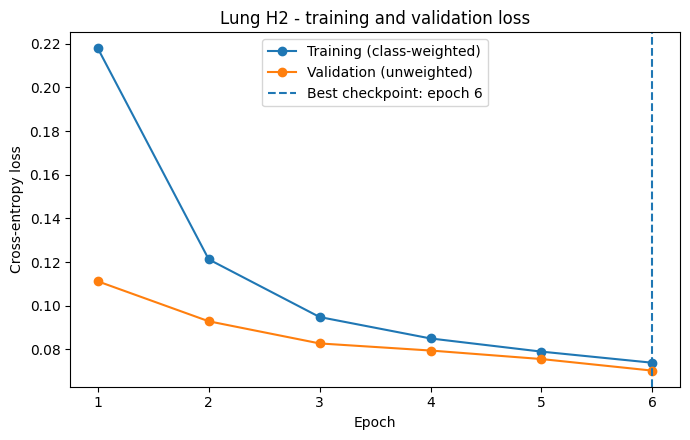

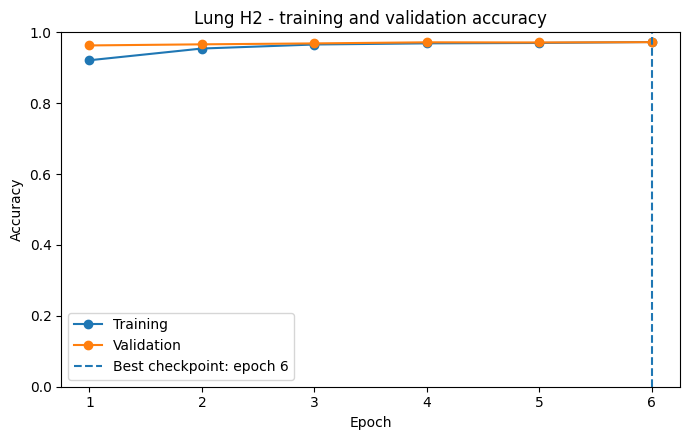

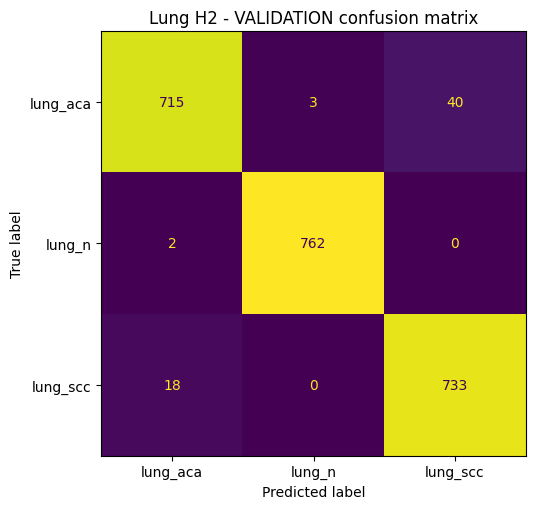

H1 vs H2 validation-only comparison:


,experiment,backbone,evaluation_split,n_images,accuracy,macro_f1,source
0,H1_MobileNetV2_frozen_seed42,MobileNetV2,validation,2273,0.970963,0.970826,H1 saved validation_metrics.json
1,H2_EfficientNetB0_frozen_seed42,EfficientNetB0,validation,2273,0.972283,0.972158,H2 best-checkpoint validation in this notebook


,file,KiB
0,H2_EfficientNetB0_frozen_seed42_evidence.zip,16554.9
1,RUN_SUMMARY.md,2.2
2,artifact_checksums.json,2.3
3,best_model.keras,16690.4
4,class_mapping.json,0.0
5,comparison_h1_h2_validation.csv,0.3
6,configuration.json,3.0
7,data_checks.json,0.7
8,environment.json,0.5
9,evaluation_environment.json,0.5



Results directory:
/content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H2_EfficientNetB0_frozen_seed42
H2 validation accuracy: 97.2283%
H2 validation macro-F1: 0.9722
Held-out test: not evaluated.


In [ ]:
# Export figures, the run summary, checksums, and evidence archive.
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

if sha256_file(RUN_DIR / 'best_model.keras') != validation_metrics['checkpoint_sha256']:
    raise ValueError('Checkpoint fingerprint changed after validation evaluation.')
epoch_numbers = history_df['epoch'].to_numpy(dtype=int) + 1

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epoch_numbers, history_df['loss'], marker='o', label='Training (class-weighted)')
ax.plot(epoch_numbers, history_df['val_loss'], marker='o', label='Validation (unweighted)')
ax.axvline(best_epoch, linestyle='--', label=f'Best checkpoint: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Lung H2 - training and validation loss')
ax.set_xticks(epoch_numbers)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_loss.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epoch_numbers, history_df['accuracy'], marker='o', label='Training')
ax.plot(epoch_numbers, history_df['val_accuracy'], marker='o', label='Validation')
ax.axvline(best_epoch, linestyle='--', label=f'Best checkpoint: epoch {best_epoch}')
ax.set(xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1), title='Lung H2 - training and validation accuracy')
ax.set_xticks(epoch_numbers)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'training_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5.2))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, values_format='d', colorbar=False)
ax.set_title('Lung H2 - VALIDATION confusion matrix')
fig.tight_layout()
fig.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Cross-check the prior H1 result against the SAME source manifest before comparison.
H1_RUN_DIR = LUNG / 'results' / 'H1_MobileNetV2_frozen_seed42'
comparison_filename = 'comparison_h1_h2_validation.csv'
comparison_note = 'H1 comparison unavailable: inspect the original H1 saved evidence separately.'
if (H1_RUN_DIR / 'validation_metrics.json').is_file() and (H1_RUN_DIR / 'configuration.json').is_file():
    h1_config = read_json(H1_RUN_DIR / 'configuration.json')
    h1_metrics = read_json(H1_RUN_DIR / 'validation_metrics.json')
    if h1_config.get('source_sha256', {}).get('manifest') != CONFIG['source_sha256']['manifest']:
        raise ValueError('H1/H2 manifests differ; comparison would be invalid.')
    if h1_config.get('class_to_id') != CONFIG['class_to_id']:
        raise ValueError('H1/H2 class mappings differ; comparison would be invalid.')
    if h1_config.get('image_counts') != CONFIG['image_counts']:
        raise ValueError('H1/H2 image split counts differ; comparison would be invalid.')
    if h1_metrics.get('evaluation_split') != 'validation' or h1_metrics.get('n_images') != len(val_df):
        raise ValueError('H1 comparison is not from the same-size validation partition.')
    if h1_metrics.get('held_out_test_evaluated') is not False:
        raise ValueError('H1 reference unexpectedly reports test use.')
    for metric_name in ['accuracy', 'macro_f1']:
        if not np.isfinite(float(h1_metrics[metric_name])) or not 0 <= float(h1_metrics[metric_name]) <= 1:
            raise ValueError(f'Invalid H1 validation metric: {metric_name}.')
    comparison = pd.DataFrame([
        {'experiment': 'H1_MobileNetV2_frozen_seed42', 'backbone': 'MobileNetV2',
         'evaluation_split': 'validation', 'n_images': len(val_df),
         'accuracy': float(h1_metrics['accuracy']), 'macro_f1': float(h1_metrics['macro_f1']),
         'source': 'H1 saved validation_metrics.json'},
        {'experiment': RUN_NAME, 'backbone': 'EfficientNetB0',
         'evaluation_split': 'validation', 'n_images': len(val_df),
         'accuracy': validation_metrics['accuracy'], 'macro_f1': validation_metrics['macro_f1'],
         'source': 'H2 best-checkpoint validation in this notebook'},
    ])
    comparison.to_csv(RUN_DIR / comparison_filename, index=False)
    comparison_note = (
        f"H1 validation accuracy={float(h1_metrics['accuracy']):.6f}, "
        f"macro-F1={float(h1_metrics['macro_f1']):.6f}; "
        f"H2 validation accuracy={validation_metrics['accuracy']:.6f}, "
        f"macro-F1={validation_metrics['macro_f1']:.6f}. "
        'Both use the same saved source-group manifest; neither is a final test result.'
    )
    print('H1 vs H2 validation-only comparison:')
    display(comparison)
else:
    print('Prior H1 metrics/configuration not accessible; H2 validation evidence is still preserved.')

summary = f"""# {RUN_NAME} - measured run summary

## Scope
Frozen ImageNet EfficientNetB0 baseline with a three-class head. No fine-tuning,
stain normalization, extra online augmentation, fusion, Grad-CAM, or final test evaluation.
The source archive already includes augmented images.

## Data and protocol
Training images: {len(train_df):,}; validation images: {len(val_df):,}.
Held-out test images: {EXPECTED_IMAGES['test']:,}; not evaluated.
Existing source-group split retained; not patient-level or external-hospital separation.
Class mapping: {json.dumps(class_to_id, sort_keys=True)}.
RGB images are resized with padding to 224 x 224 outside the model.
EfficientNetB0 contains native Keras preprocessing; model input is float32 RGB [0, 255].
Batch size: {BATCH_SIZE}; seed: {SEED}; Adam learning rate: {LEARNING_RATE}.
Training loss is class-weighted; validation loss is unweighted.

## Validation results
- Epochs completed: {len(history_df)} (maximum requested: {MAX_EPOCHS}).
- Best epoch by validation loss: {best_epoch} (one-based).
- Validation loss: {validation_metrics['validation_loss']:.6f}.
- Validation accuracy: {validation_metrics['accuracy']:.6f}.
- Validation macro-F1: {validation_metrics['macro_f1']:.6f}.
- Validation weighted-F1: {validation_metrics['weighted_f1']:.6f}.

## H1 versus H2 (validation only)
{comparison_note}

Confusion-matrix rows are true classes; columns are predicted classes.
Per-class metrics and predictions are in the accompanying CSV/TXT files.

## Limits and interpretation
These are image-level validation metrics on related images within reconstructed
source-image groups. They do not establish independent patient-level performance,
clinical reliability, or external generalization. Softmax scores are not calibrated
clinical probabilities. Source-group annotations were reused, not reconstructed here.
The CSV epoch log is zero-based; figures and this summary are one-based.

## Provenance
Checkpoint SHA-256: {validation_metrics['checkpoint_sha256']}
Manifest SHA-256: {CONFIG['source_sha256']['manifest']}
Archive SHA-256: {ARCHIVE_SHA256}
Notebook revision: {CONFIG['notebook_revision']}

The executed notebook is retained separately from the evidence archive.
"""
(RUN_DIR / 'RUN_SUMMARY.md').write_text(summary, encoding='utf-8')
required_outputs = [
    'best_model.keras', 'configuration.json', 'class_mapping.json', 'environment.json',
    'data_checks.json', 'training_status.json', 'training_history.csv',
    'validation_metrics.json', 'validation_classification_report.txt',
    'validation_classification_report.csv', 'validation_predictions.csv',
    'validation_confusion_matrix.csv', 'validation_confusion_matrix.png',
    'training_loss.png', 'training_accuracy.png', 'train_val_image_index.csv',
    'evaluation_environment.json', 'model_summary.txt', 'RUN_SUMMARY.md',
]
if (RUN_DIR / comparison_filename).is_file():
    required_outputs.append(comparison_filename)
for name in required_outputs:
    path = RUN_DIR / name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'Missing or empty output: {path}')

# The checksums file does not hash itself or the evidence archive.
evidence_name = RUN_NAME + '_evidence.zip'
artifact_paths = sorted(path for path in RUN_DIR.rglob('*') if path.is_file()
                        and path.name not in {'artifact_checksums.json', evidence_name}
                        and not path.name.endswith('.tmp'))
checksums = {str(path.relative_to(RUN_DIR)): sha256_file(path) for path in artifact_paths}
save_json(RUN_DIR / 'artifact_checksums.json', checksums)
local_evidence = LOCAL_ROOT / evidence_name
with zipfile.ZipFile(local_evidence, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in artifact_paths + [RUN_DIR / 'artifact_checksums.json']:
        archive.write(path, arcname=str(Path(RUN_NAME) / path.relative_to(RUN_DIR)))
with zipfile.ZipFile(local_evidence) as archive:
    if archive.testzip() is not None:
        raise IOError('The local evidence ZIP failed its integrity check.')
shutil.copy2(local_evidence, RUN_DIR / evidence_name)
if sha256_file(local_evidence) != sha256_file(RUN_DIR / evidence_name):
    raise IOError('The evidence ZIP copy in Drive did not verify.')

display(pd.DataFrame([
    {'file': str(path.relative_to(RUN_DIR)), 'KiB': round(path.stat().st_size / 1024, 1)}
    for path in sorted(RUN_DIR.rglob('*')) if path.is_file()
]))
print('\nResults directory:')
print(RUN_DIR)
print(f'H2 validation accuracy: {validation_metrics["accuracy"]:.4%}')
print(f'H2 validation macro-F1: {validation_metrics["macro_f1"]:.4f}')
print('Held-out test: not evaluated.')


## Reproducing completed validation results

After a successful H2 run, switch the mode in Section 3 to `evaluate_saved`. In a fresh runtime, execute Sections 1–5, 7, 9 and 10 in order; Section 6 skips the disposable smoke test and Section 8 skips training in evaluation mode. Saved configurations, artifact hashes and the fixed manifest are checked before reporting metrics. **Never run Section 8 again with `train_new` on a populated H2 results directory.**

H2 and H1 are separate frozen-backbone baselines. Stain normalization, controlled color-shift robustness, feature fusion, Grad-CAM and final held-out evaluation are separate planned workflows and must not be claimed as H2 outcomes.


## Documentation and source records

- `PROJECT_HANDOFF_2026-10-19_POST_U2.md` — current project status and fixed evaluation boundaries.
- `02_Lung_MobileNetV2_Baseline.ipynb` — reviewed H1 lung split, image checks and frozen-backbone baseline.
- `03_Ultrasound_EfficientNetB0_Baseline.ipynb` — reviewed EfficientNetB0 Keras preprocessing and model verification pattern.
- `Histopathology Lung Cancer Project Proposal Sajjad.pdf` — approved stain-aware fusion and explanation scope (not implemented by H2).
- [Keras EfficientNet models](https://keras.io/api/applications/efficientnet/)
- [TensorFlow Keras model checkpoints](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ModelCheckpoint)
- [TensorFlow deterministic operations](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism)
